In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [18]:
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")

In [19]:
train.head()

,ID,date,device,site_latitude,site_longitude,humidity,temp_mean,SulphurDioxide_SO2_column_number_density,SulphurDioxide_SO2_column_number_density_amf,SulphurDioxide_SO2_slant_column_number_density,...,Cloud_cloud_top_height,Cloud_cloud_base_pressure,Cloud_cloud_base_height,Cloud_cloud_optical_depth,Cloud_surface_albedo,Cloud_sensor_azimuth_angle,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,pm2_5
0,ID_JBYXJEUZ8X,2020-03-18,ANQ16PZJ,0.353465,32.560322,0.846844,22.038542,-0.000138,1.042629,-0.000143,...,4181.792969,69589.453125,3181.793457,7.799846,0.278111,76.618553,9.970293,-93.110069,19.214193,63.853333
1,ID_PEJJNLBUPR,2019-10-13,AB6051M4,0.390741,32.582257,0.874493,21.545833,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.507083
2,ID_21L8UZQO1T,2019-12-21,A0WN66FH,0.285751,32.578325,0.729340,23.568655,NaN,NaN,NaN,...,4440.391113,67341.109375,3440.390869,62.496590,0.416631,-97.300758,63.690605,-127.856804,40.857922,80.290833
3,ID_GNW2G8J4T8,2020-02-20,aq_41,-1.244985,29.989236,0.919271,16.338542,-0.000111,0.750228,-0.000083,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.601687
4,ID_4XOX2V6SK0,2019-04-17,aq_41,-1.244985,29.989236,0.858365,16.602083,-0.000127,0.792634,-0.000101,...,4842.057488,64347.788635,3842.057585,4.971117,0.277157,74.786025,32.583070,-57.273638,21.864529,89.642229


In [20]:
train.date=pd.to_datetime(train.date)

In [21]:
len(set(train.date[train.device=="AY2J2Q7Z"]).union(train.date[train.device=="APYZC5J7"]))

329

In [22]:
len(set(train.date).intersection(test.date))

0

In [23]:
test.date[test.device=="AB6051M4"]

8       2020-09-28
16      2020-09-03
66      2020-10-23
68      2020-11-24
101     2020-12-19
           ...    
4180    2020-08-30
4228    2020-08-23
4229    2020-10-16
4250    2020-08-21
4251    2020-11-07
Name: date, Length: 134, dtype: object

In [24]:
train.pm2_5[train.device=="AY2J2Q7Z"]

8        41.652083
49       86.780833
129      75.980000
317      58.477083
357      47.162917
           ...    
9843     73.515417
9865     73.300833
9888    101.975417
9894     87.984167
9916     51.903333
Name: pm2_5, Length: 328, dtype: float64

<AxesSubplot:xlabel='Lag', ylabel='Autocorrelation'>

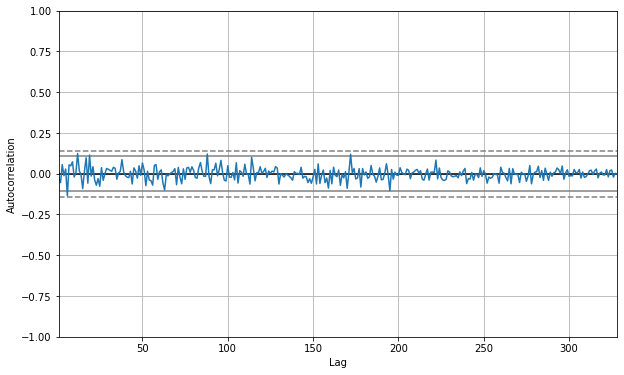

In [25]:
plt.figure(figsize=(10,6))
pd.plotting.autocorrelation_plot(train.pm2_5[train.device=="AB6051M4"])

In [26]:
train["pos"]=train.site_latitude.map(str)+"-"+train.site_longitude.map(str)
pos_test=test.site_latitude.map(str)+"-"+test.site_longitude.map(str)

In [27]:
train.pos.unique().shape

(48,)

In [28]:
train.device.unique().shape

(34,)

c:\Users\user\Anaconda3\lib\site-packages\pandas\plotting\_matplotlib\misc.py:458: RuntimeWarning: invalid value encountered in double_scalars
  return ((data[: n - h] - mean) * (data[h:] - mean)).sum() / n / c0
c:\Users\user\Anaconda3\lib\site-packages\ipykernel_launcher.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  


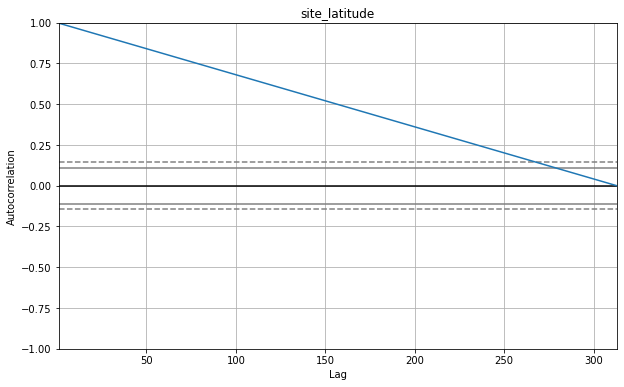

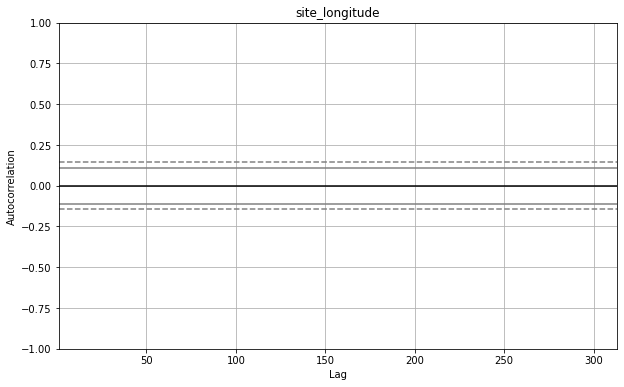

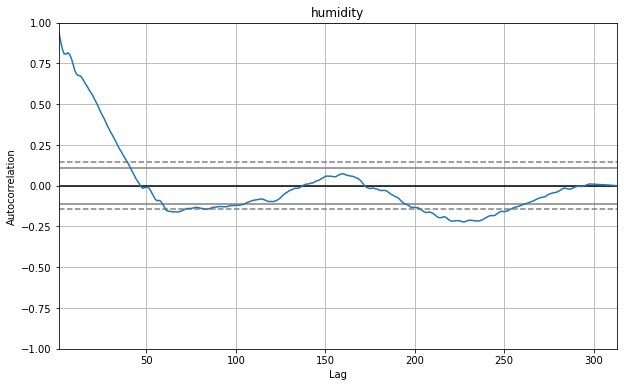

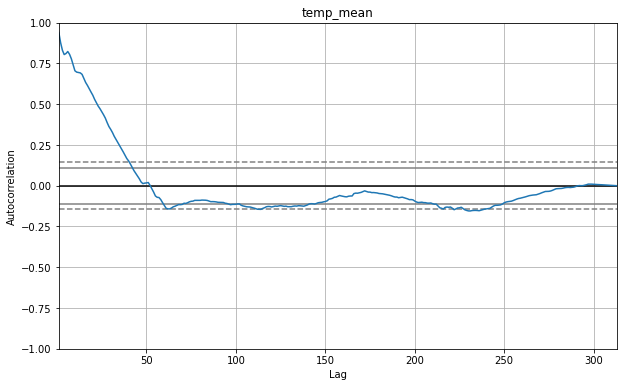

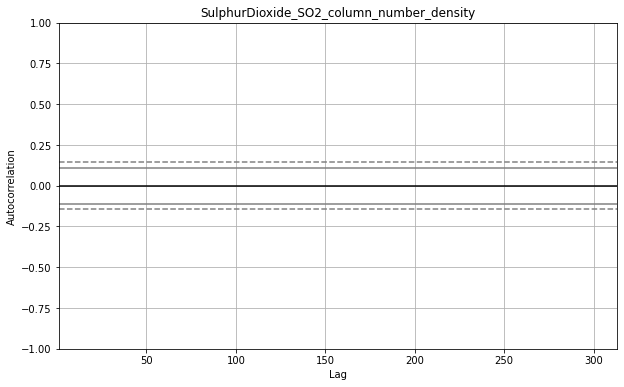

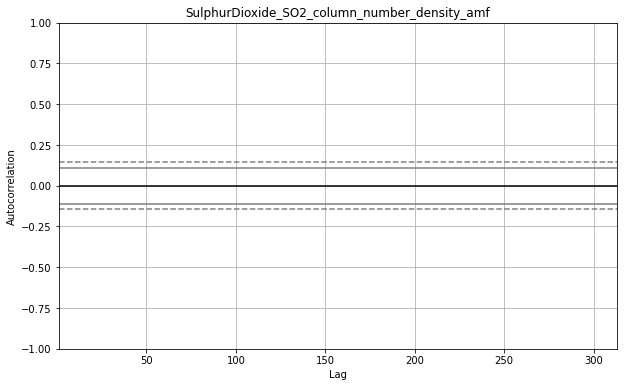

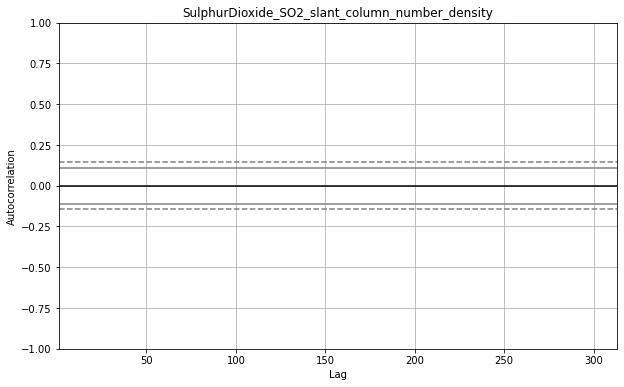

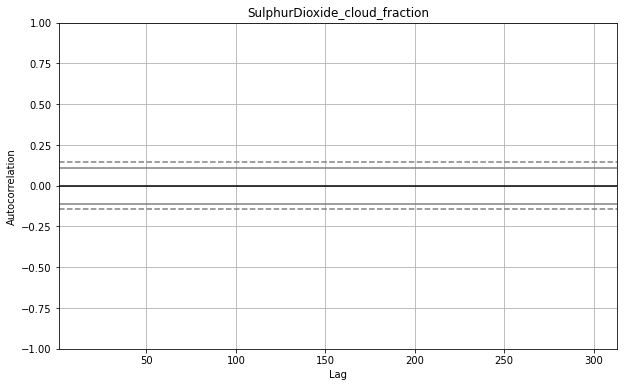

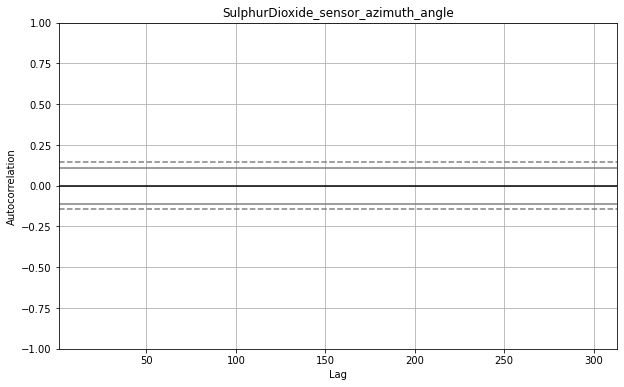

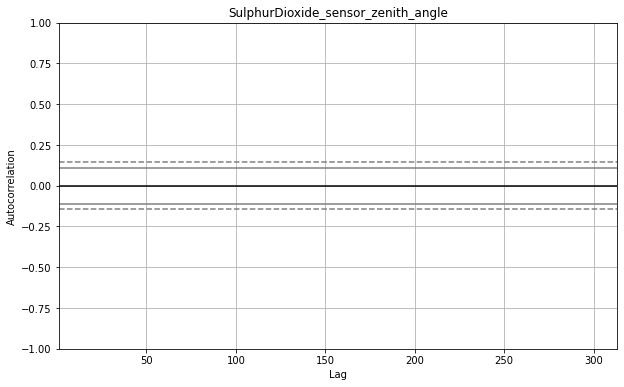

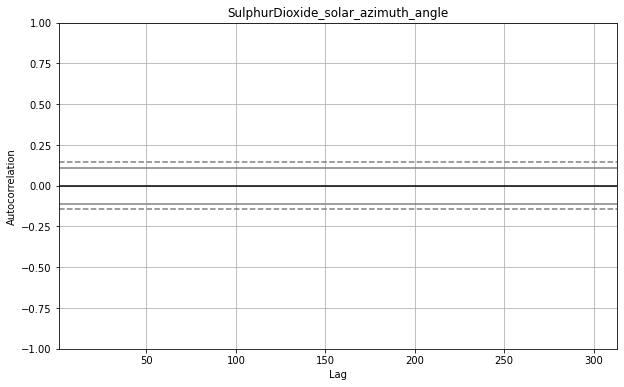

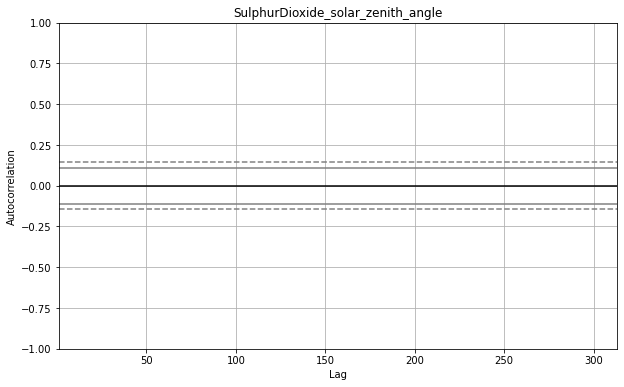

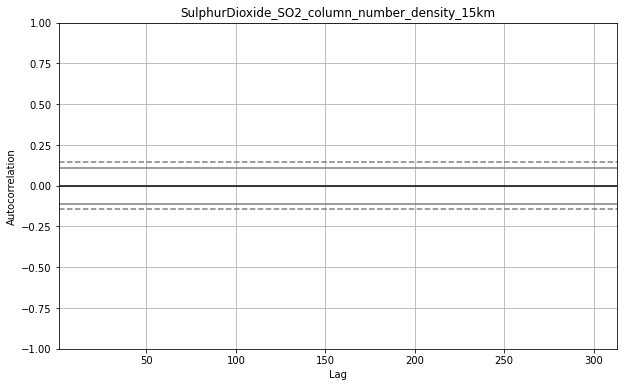

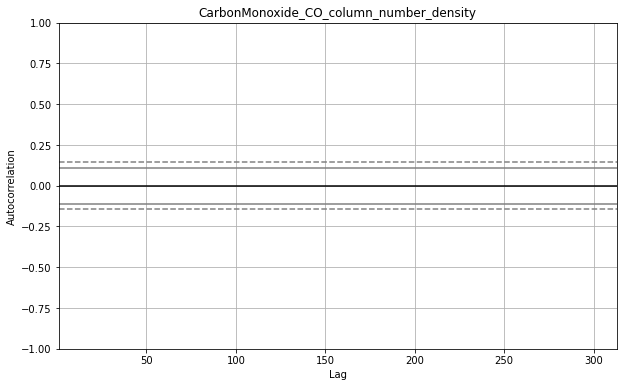

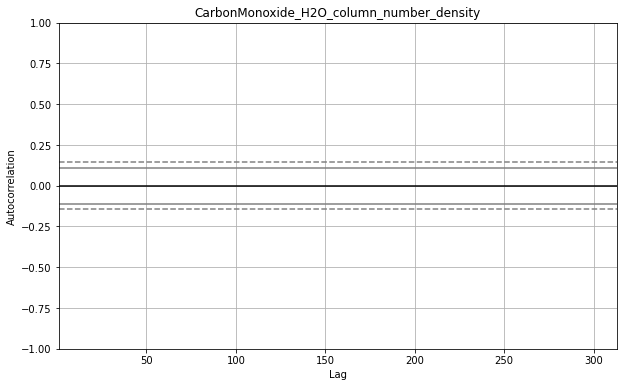

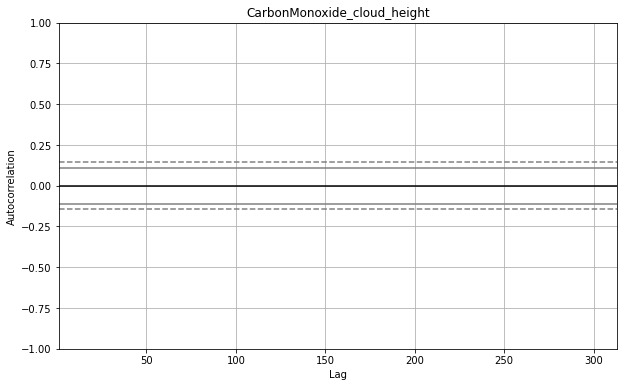

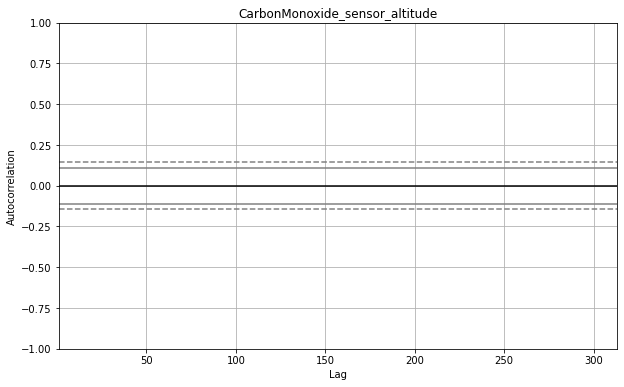

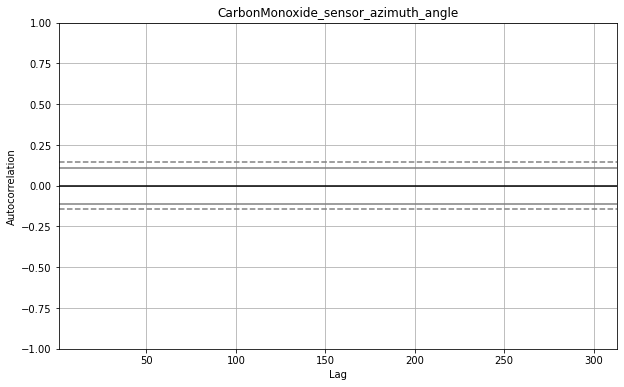

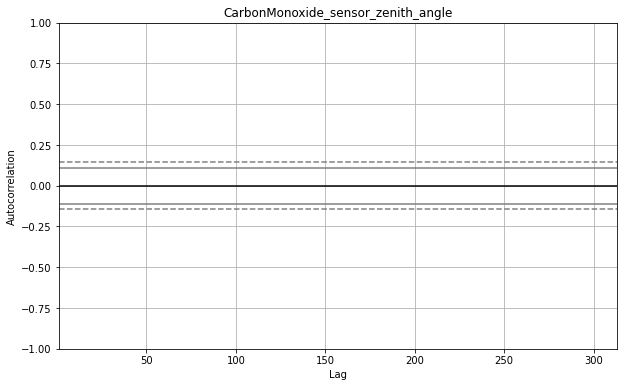

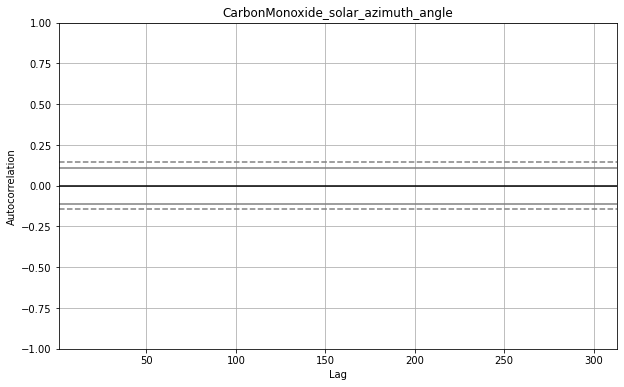

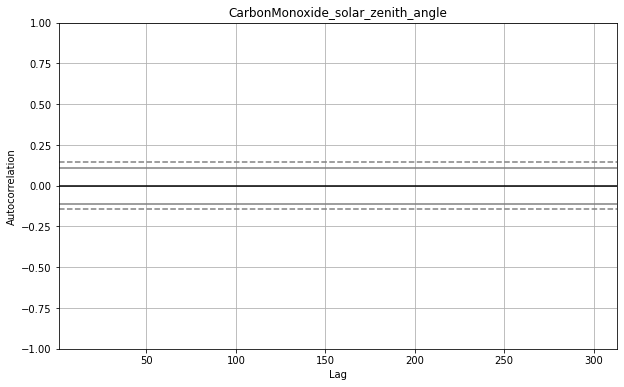

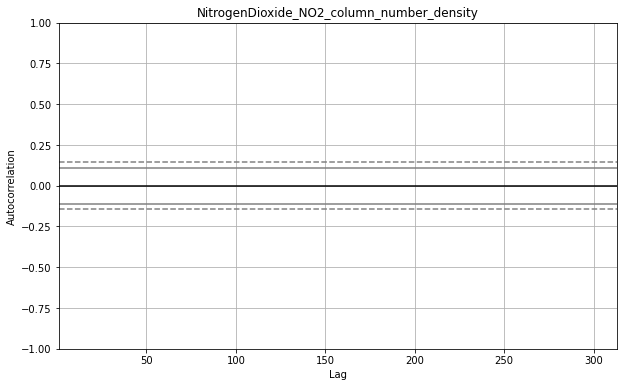

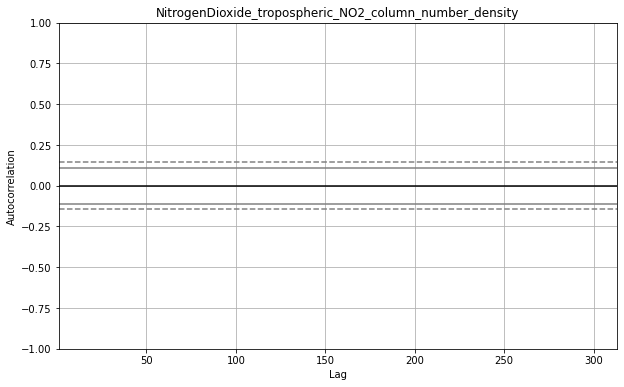

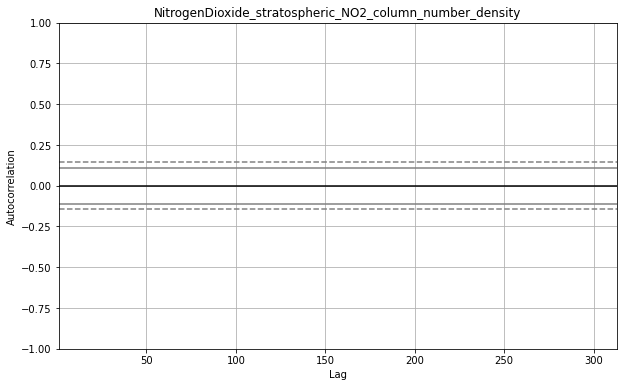

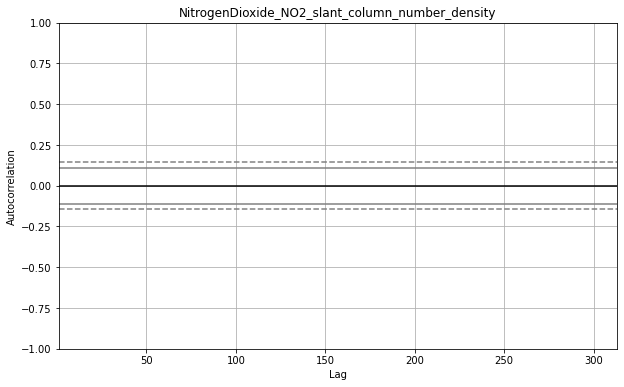

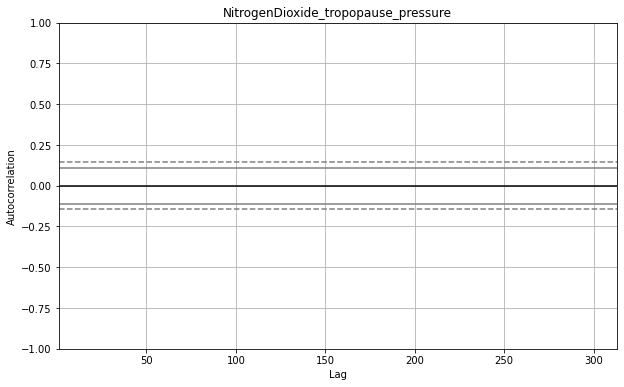

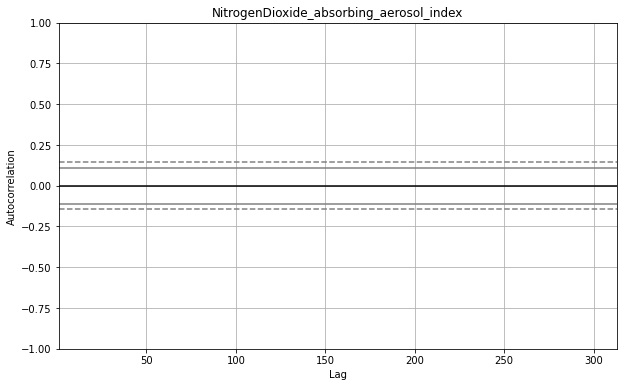

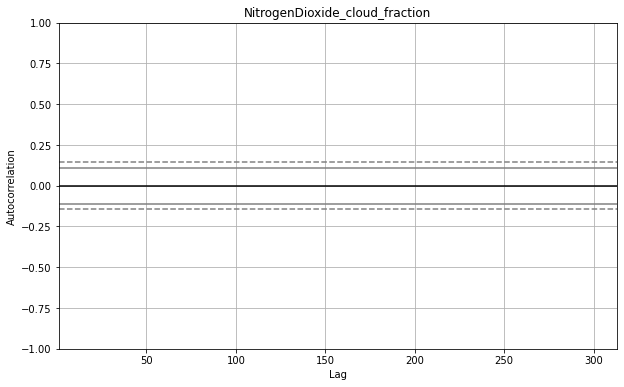

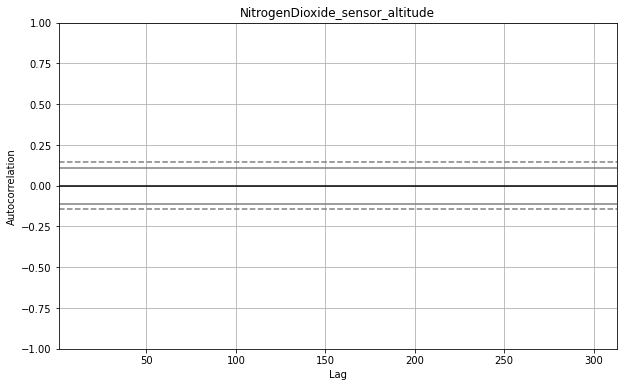

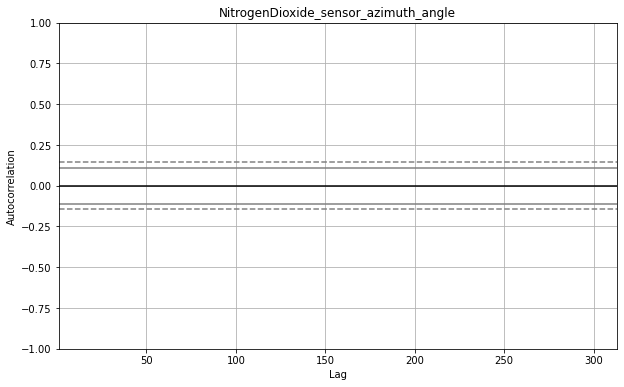

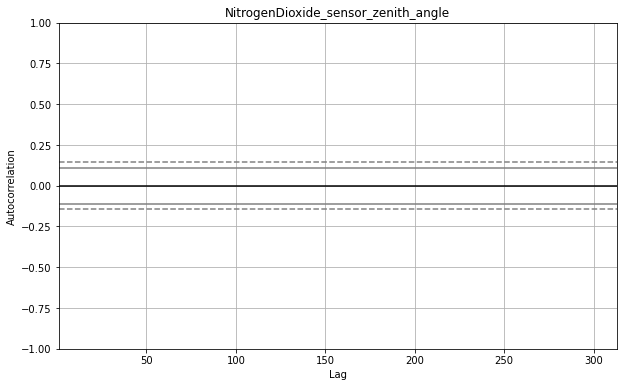

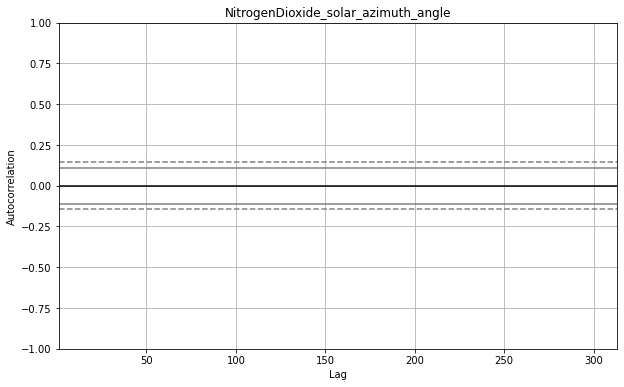

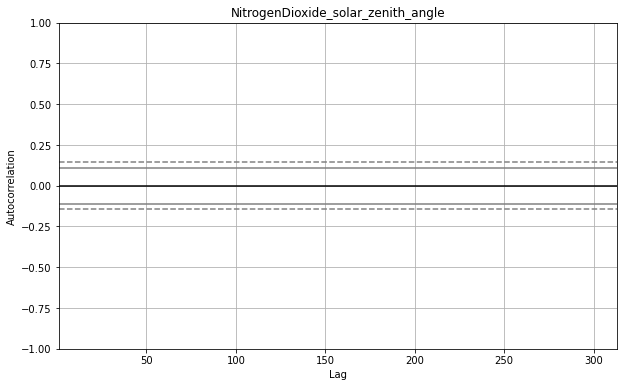

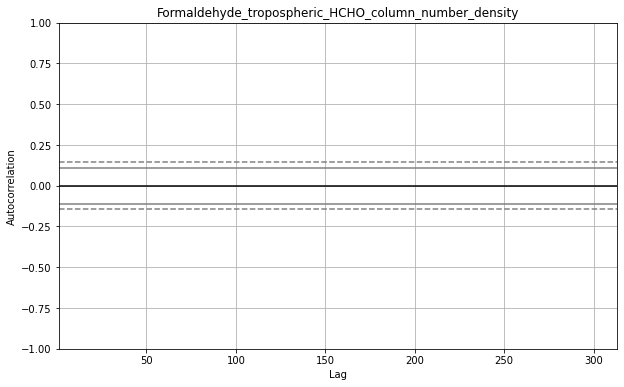

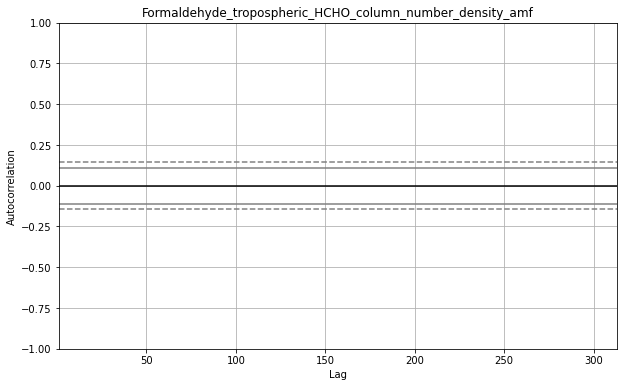

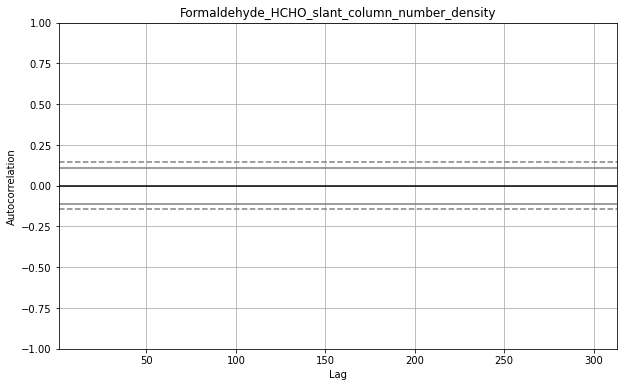

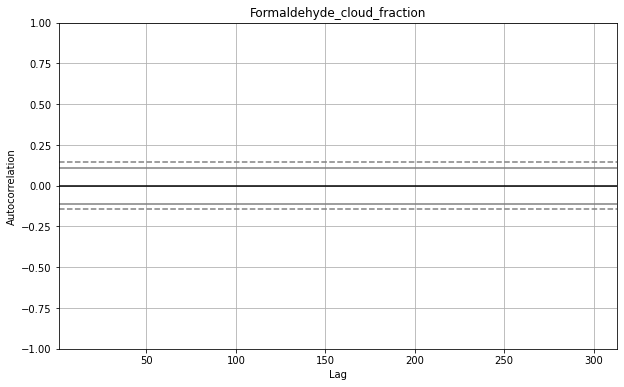

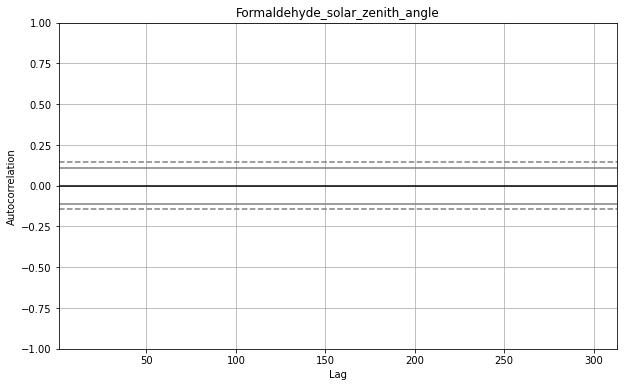

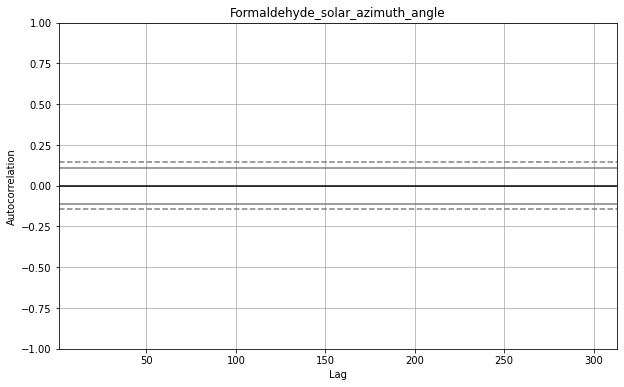

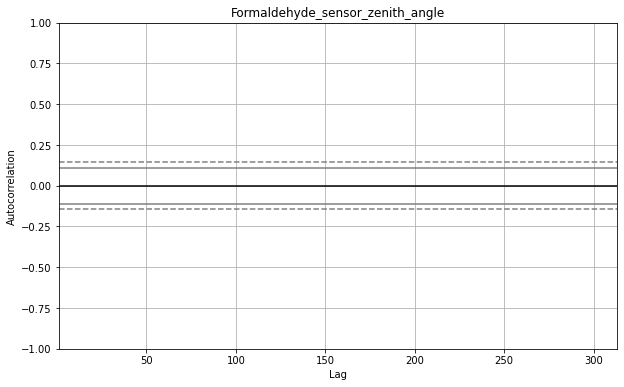

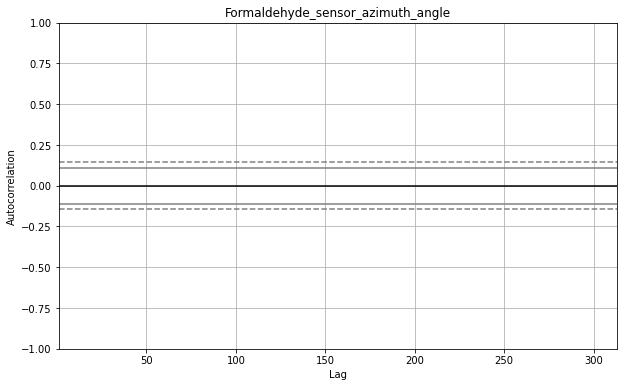

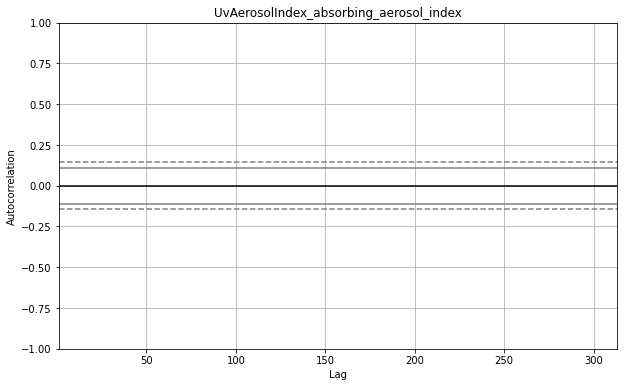

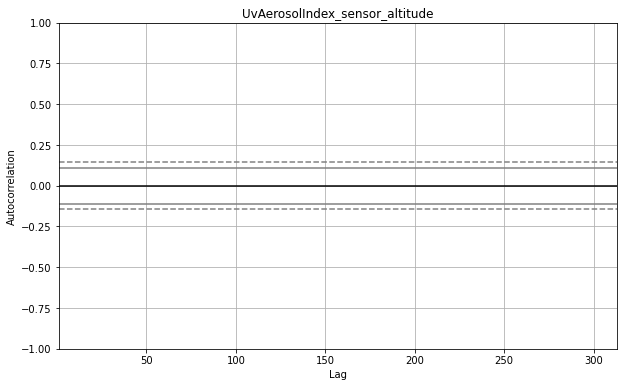

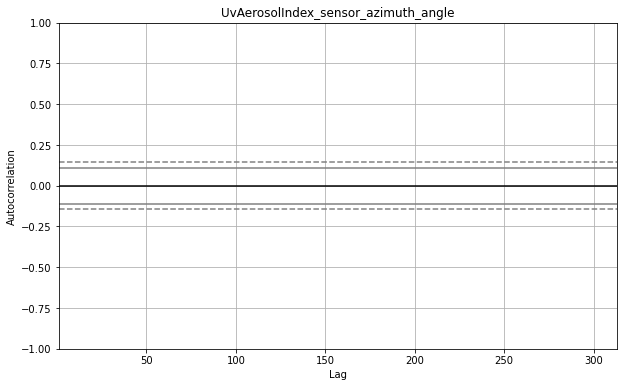

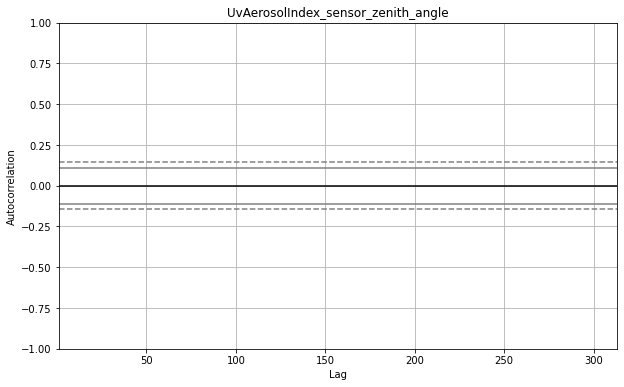

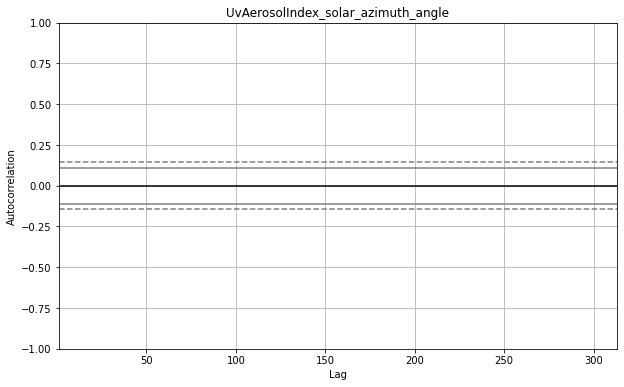

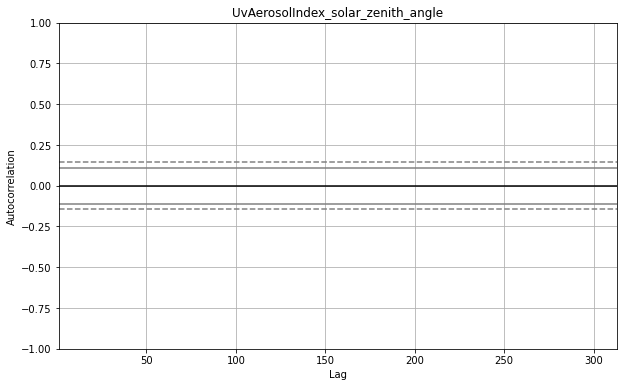

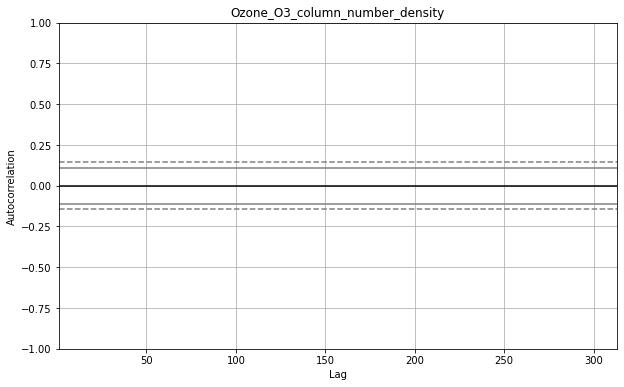

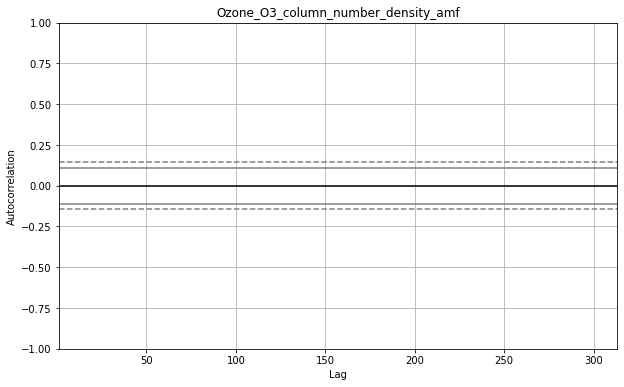

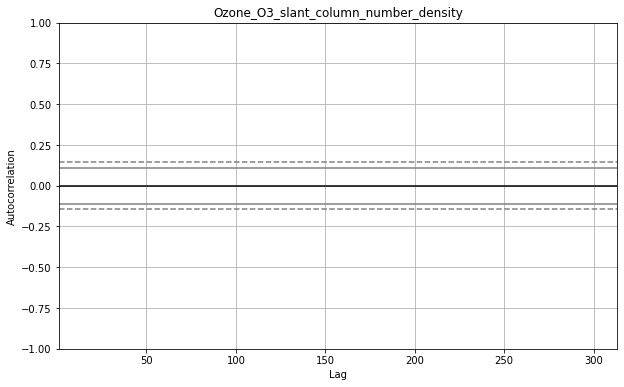

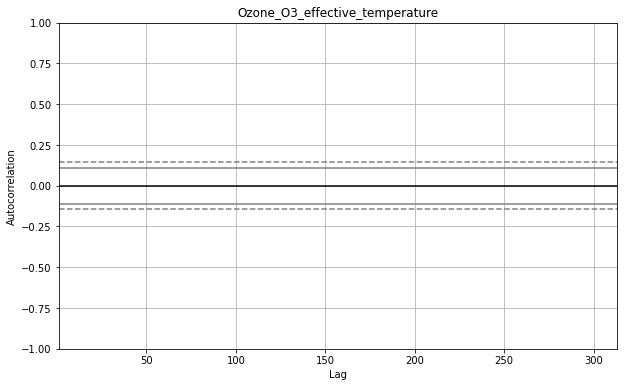

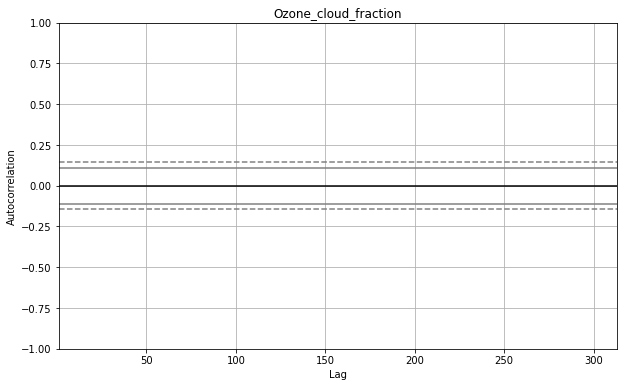

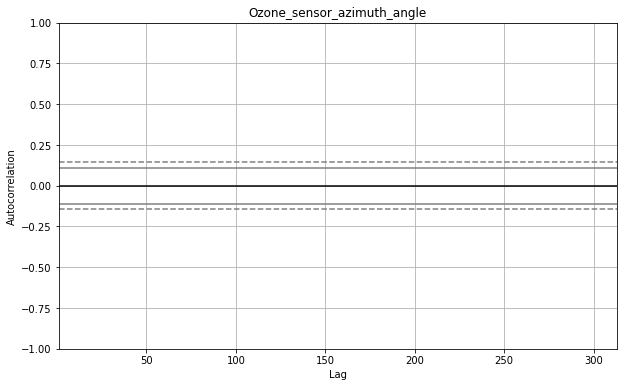

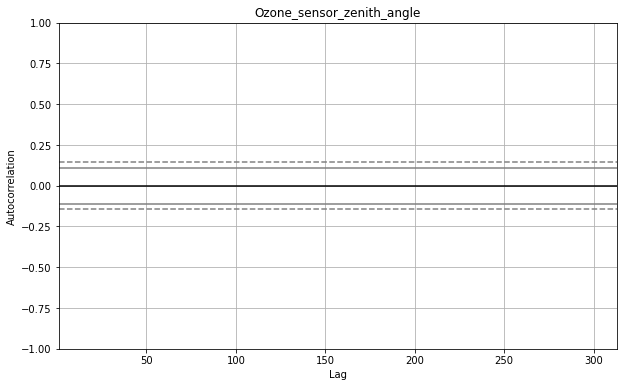

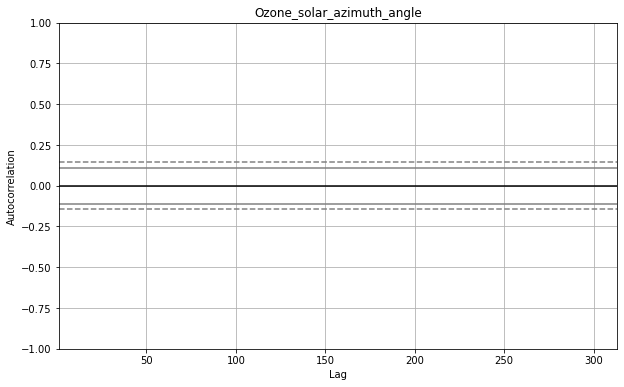

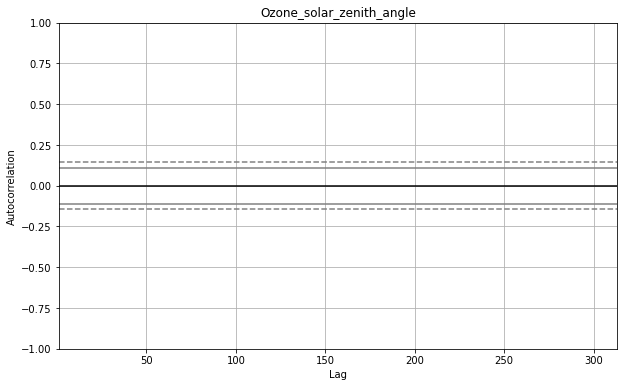

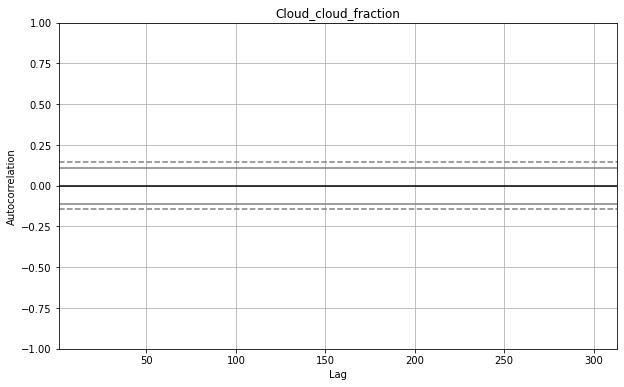

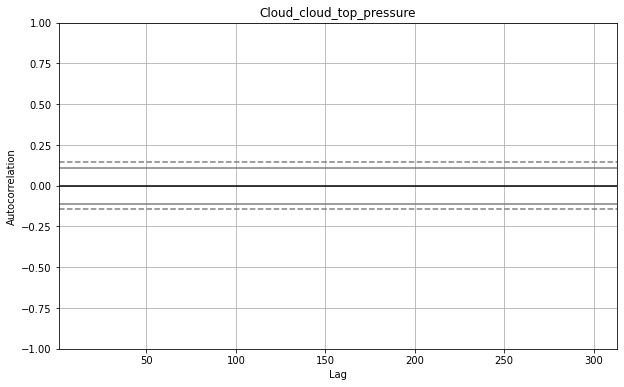

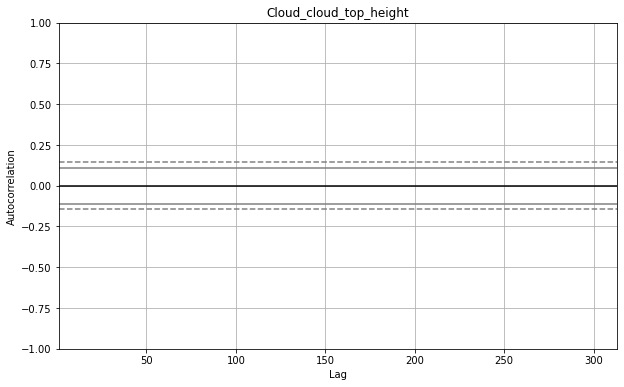

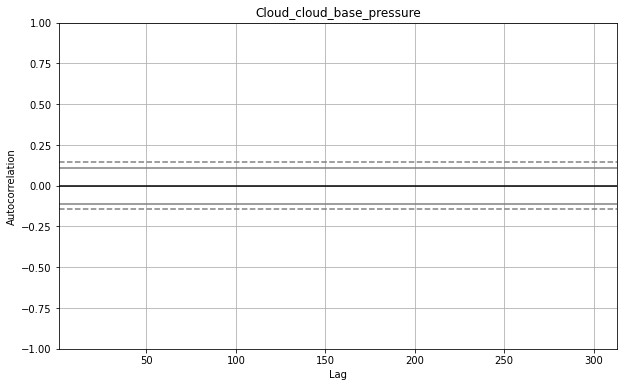

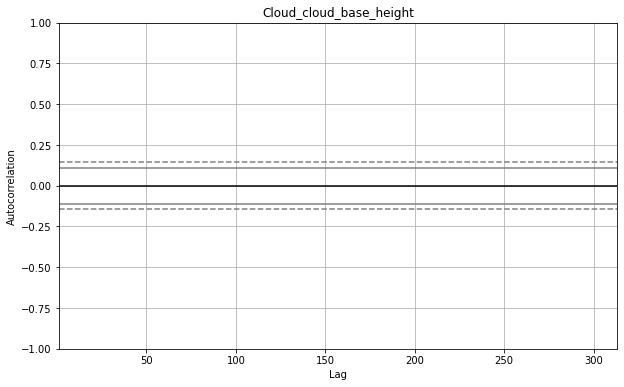

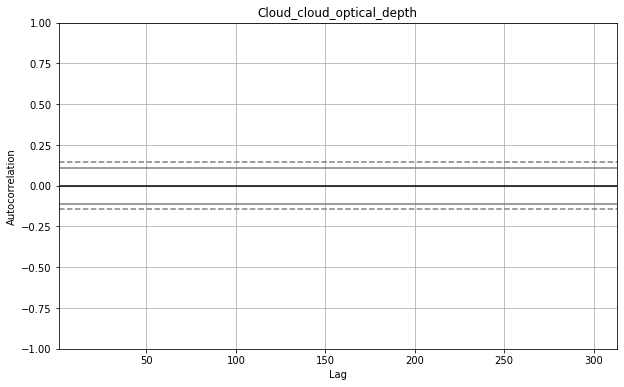

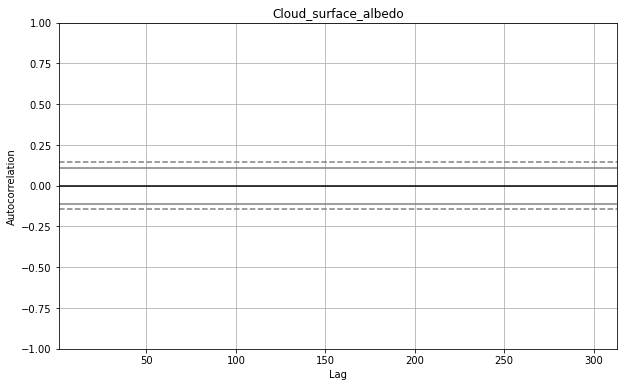

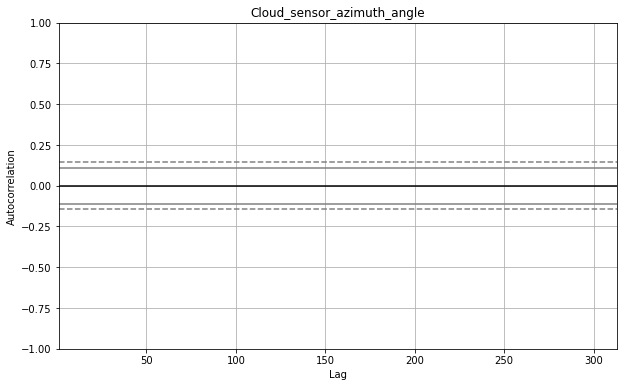

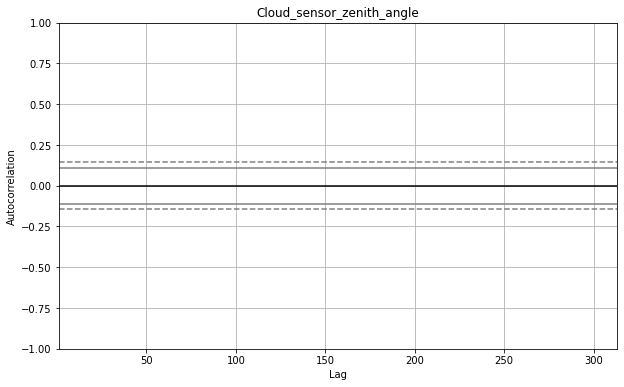

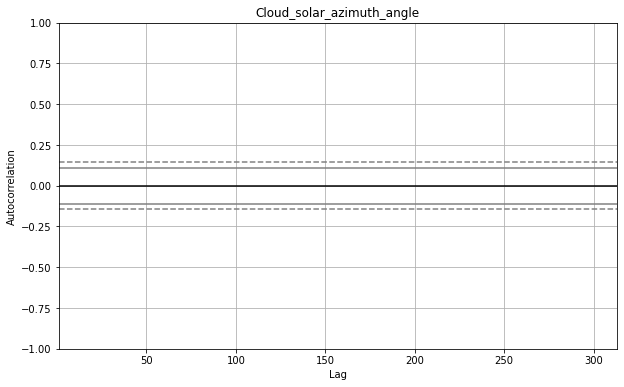

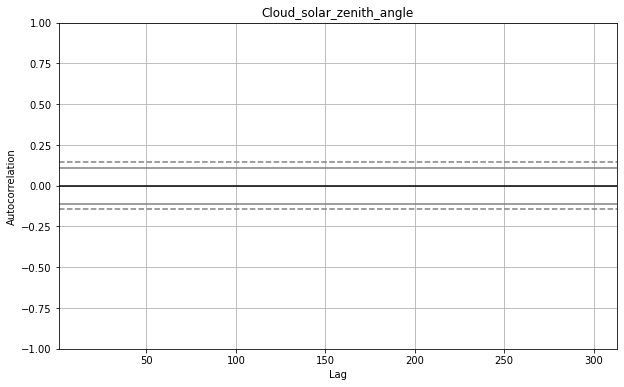

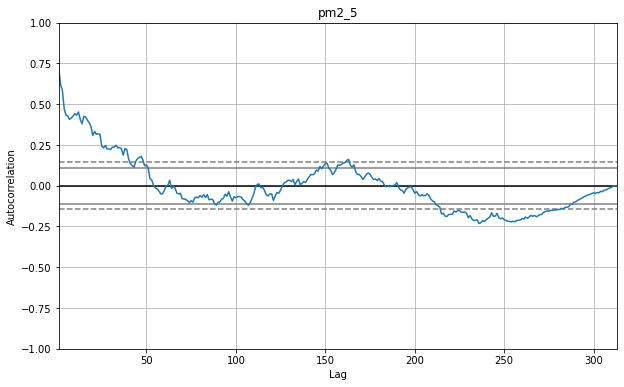

In [39]:
for column_name in train.select_dtypes(["float","int"]).columns:
    plt.figure(figsize=(10,6))
    pd.plotting.autocorrelation_plot(train[train.pos=="0.3534645999999999-32.5603223"].sort_values(by=['date'])[column_name])
    plt.title(column_name)


### Format Dataset

In [60]:
# Load train dataset
df=pd.read_csv("train.csv")

#Create new feature
df.date=pd.DatetimeIndex(df.date)
df["year"]=df.date.dt.year
df["month"]=df.date.dt.month.map(str)
df["day"]=df.date.dt.day.map(str)
df['day_of_week']=df.date.dt.dayofweek.map(str)
df["week"]=df.date.dt.isocalendar().week.map(str)
df["site"]=df.site_latitude.map(str)+"-"+df.site_longitude.map(str)

# Format dataset
df=df.sort_values(by=["date", "site"]).reset_index(drop=True)

#Select used columns
#df.drop(["ID", "date", "device", "site_latitude", "site_longitude","year"], axis=1, inplace=True)
df=df[["date","site","humidity","temp_mean","day","day_of_week","week","month"]]

In [59]:
df.head()

,humidity,temp_mean,SulphurDioxide_SO2_column_number_density,SulphurDioxide_SO2_column_number_density_amf,SulphurDioxide_SO2_slant_column_number_density,SulphurDioxide_cloud_fraction,SulphurDioxide_sensor_azimuth_angle,SulphurDioxide_sensor_zenith_angle,SulphurDioxide_solar_azimuth_angle,SulphurDioxide_solar_zenith_angle,...,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,pm2_5,month,day,day_of_week,week,year-month,site
0,0.846583,22.641667,-0.000251,0.527936,-0.000133,0.116888,-98.333313,52.513481,-95.526909,28.235924,...,52.513670,-95.490160,28.237128,31.415000,3,14,3,11,2019-3,0.059604-32.46032
1,0.783833,24.325000,-0.000132,0.562716,-0.000074,0.023798,-100.671768,26.636999,-95.566139,23.584146,...,26.637129,-95.566147,23.584166,28.940000,3,15,4,11,2019-3,0.059604-32.46032
2,0.741972,25.725000,-0.000169,0.550671,-0.000093,0.030852,76.478450,11.737689,-95.645902,18.961725,...,11.730469,-95.646289,18.962576,34.349272,3,16,5,11,2019-3,0.059604-32.46032
3,0.748049,24.607986,-0.000286,0.669683,-0.000192,0.000000,73.626366,43.742661,-95.708099,14.360106,...,NaN,NaN,NaN,43.131879,3,17,6,11,2019-3,0.059604-32.46032
4,0.735576,24.857639,-0.000120,0.656247,-0.000079,0.010367,71.646456,62.290205,-96.195684,9.756710,...,62.237459,-96.222612,9.773934,30.584458,3,18,0,12,2019-3,0.059604-32.46032


In [75]:
df.groupby(["site","month"])["humidity"].transform(np.mean,np.std)

0       0.785321
1       0.785321
2       0.785321
3       0.785321
4       0.785321
          ...   
9918    0.789652
9919    0.660901
9920    0.773130
9921    0.791691
9922    0.789539
Name: humidity, Length: 9923, dtype: float64

In [82]:
df=df.set_index("date")

In [84]:
df.groupby(["site"]).resample("M").mean()

humidity  temp_mean
site                         date                           
-1.244985-29.989235999999995 2019-04-30  0.895021  17.160460
                             2019-05-31  0.922922  16.840854
                             2019-06-30  0.885768  16.687244
                             2019-07-31  0.821514  16.064282
                             2019-08-31  0.772471  16.887876
...                                           ...        ...
0.391478-32.62583            2020-04-30       NaN        NaN
                             2020-05-31  0.845593  22.477989
                             2020-06-30  0.805685  22.125799
                             2020-07-31  0.793527  21.622023
                             2020-08-31  0.789539  22.434257

[533 rows x 2 columns]

In [32]:
# Load test dataset
test_df = pd.read_csv("test.csv") 
submit = pd.read_csv("SampleSubmission.csv")

# Create new feature
test_df.date=pd.DatetimeIndex(test_df.date)
test_df["year"]=test_df.date.dt.year
test_df["month"]=test_df.date.dt.month.map(str)
test_df["day"]=test_df.date.dt.day.map(str)
test_df['day_of_week']=test_df.date.dt.dayofweek.map(str)
test_df["week"]=test_df.date.dt.isocalendar().week.map(str)
test_df["year-month"]=test_df.year.map(str)+"-"+test_df.month.map(str)
test_df["site"]=test_df.site_latitude.map(str)+"-"+test_df.site_longitude.map(str)

# Format test dataset
test_df=test_df.sort_values(by=["date", "site"]).reset_index()

# Select used columnns
cols = [t for t in test_df.columns if t not in df.columns]
test_df = test_df.drop(cols, axis=1)
# test_df.fillna(0,inplace=True)

In [33]:
test_df.head()

,index,date,humidity,temp_mean,SulphurDioxide_SO2_column_number_density,SulphurDioxide_SO2_column_number_density_amf,SulphurDioxide_SO2_slant_column_number_density,SulphurDioxide_cloud_fraction,SulphurDioxide_sensor_azimuth_angle,SulphurDioxide_sensor_zenith_angle,...,Cloud_sensor_azimuth_angle,Cloud_sensor_zenith_angle,Cloud_solar_azimuth_angle,Cloud_solar_zenith_angle,month,day,day_of_week,week,year-month,site
0,3665,2020-08-20,0.609326,17.466319,NaN,NaN,NaN,NaN,NaN,NaN,...,73.810173,43.116596,-49.163383,20.785456,8,20,3,34,2020-8,-1.244985-29.989235999999995
1,891,2020-08-20,0.782847,22.381597,0.000276,0.865604,0.000240,0.000000,75.278811,25.998585,...,NaN,NaN,NaN,NaN,8,20,3,34,2020-8,0.059604-32.46032
2,121,2020-08-20,0.806278,22.701042,0.000054,0.879693,0.000047,0.251945,75.393561,24.544381,...,75.393824,24.546721,-56.439372,22.010322,8,20,3,34,2020-8,0.2650066-32.6255992
3,1457,2020-08-20,0.806278,22.701042,0.000040,0.901875,0.000036,0.281788,75.392685,24.546827,...,75.392677,24.546679,-56.481930,21.994705,8,20,3,34,2020-8,0.28368-32.60048
4,3557,2020-08-20,0.792427,23.349306,0.000218,0.857963,0.000187,0.210323,75.368164,24.836802,...,75.368156,24.836651,-56.407757,21.969639,8,20,3,34,2020-8,0.2857506-32.5783253


In [34]:
df[["date","pm2_5"]][df.site=="0.3534645999999999-32.5603223"]

,date,pm2_5
711,2019-09-28,41.468750
736,2019-09-29,58.917500
761,2019-09-30,25.786250
787,2019-10-01,48.735000
811,2019-10-02,25.665000
...,...,...
9775,2020-08-15,83.342500
9808,2020-08-16,115.452500
9840,2020-08-17,139.315417
9871,2020-08-18,95.790000


In [35]:
set(test_df.site).difference(df.site)

{'0.332609275-32.61004743'}

In [33]:
set(df.site).difference(test_df.site)

{'0.3795622999999999-32.553714'}

In [29]:
test_df[["date"]][test_df.site=="0.3534645999999999-32.5603223"]

,date
15,2020-08-20
45,2020-08-21
76,2020-08-22
108,2020-08-23
141,2020-08-24
...,...
4119,2020-12-27
4150,2020-12-28
4181,2020-12-29
4212,2020-12-30


In [ ]:
-1.244985-29.989236

-1.244985-29.989235999999995 